In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/heart_cleveland_upload.csv")
df = df.rename(columns={"condition": "target"})
print(f"Cleveland dataset shape: {df.shape}")
df.head()


Cleveland dataset shape: (297, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


## Cleveland Heart Disease Dataset — Column Reference

This notebook uses the supplied `data/heart_cleveland_upload.csv` file. It has 297 complete records and 13 predictor columns. The source outcome column is `condition`; the loading cell renames it to `target` for the modeling steps below. In this file, **0 means no heart disease and 1 means heart disease present**.

### Continuous features

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `thalach` | Maximum heart rate reached during exercise testing |
| `oldpeak` | ST depression induced by exercise relative to rest |

### Binary features

| Column | Meaning | Values |
|---|---|---|
| `sex` | Sex code in this dataset | 0 = female, 1 = male |
| `fbs` | Fasting blood sugar above 120 mg/dl | 0 = no, 1 = yes |
| `exang` | Exercise-induced angina | 0 = no, 1 = yes |

### Categorical features

- `cp`: 0 typical angina, 1 atypical angina, 2 non-anginal pain, 3 asymptomatic.
- `restecg`: 0 normal, 1 ST-T wave abnormality, 2 probable/definite left ventricular hypertrophy.
- `slope`: 0 upsloping, 1 flat, 2 downsloping.
- `ca`: number of major vessels visible by fluoroscopy (0–3).
- `thal`: this uploaded file uses 0 normal, 1 fixed defect, 2 reversible defect. These values are a recoded version of the original Cleveland encodings.



In [2]:
print("Data Types and Null Counts")

df.info()
print()
print("Descriptive statistics")
df.describe().round(2)

Data Types and Null Counts
<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    int64  
 1   sex       297 non-null    int64  
 2   cp        297 non-null    int64  
 3   trestbps  297 non-null    int64  
 4   chol      297 non-null    int64  
 5   fbs       297 non-null    int64  
 6   restecg   297 non-null    int64  
 7   thalach   297 non-null    int64  
 8   exang     297 non-null    int64  
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    int64  
 11  ca        297 non-null    int64  
 12  thal      297 non-null    int64  
 13  target    297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB

Descriptive statistics


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00
mean,54.54,0.68,2.16,131.69,247.35,0.14,1.00,149.60,0.33,1.06,0.60,0.68,0.84,0.46
std,9.05,0.47,0.96,17.76,52.00,0.35,0.99,22.94,0.47,1.17,0.62,0.94,0.96,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,48.00,0.00,2.00,120.00,211.00,0.00,0.00,133.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,56.00,1.00,2.00,130.00,243.00,0.00,1.00,153.00,0.00,0.80,1.00,0.00,0.00,0.00
75%,61.00,1.00,3.00,140.00,276.00,0.00,2.00,166.00,1.00,1.60,1.00,1.00,2.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,3.00,2.00,1.00


### Notes from the descriptive statistics

- The file contains 297 records. Age ranges from 29 to 77 years (mean about 54.5).
- Resting blood pressure ranges from 94 to 200 mm Hg; cholesterol ranges from 126 to 564 mg/dl, with a long upper tail.
- Maximum heart rate ranges from 71 to 202; `oldpeak` ranges from 0 to 6.2 and is right-skewed.
- The outcome is moderately balanced: 137 records (46.1%) have `target=1`, and 160 (53.9%) have `target=0`.
- These are descriptions of this small historical dataset, not population estimates.


In [3]:
print(df.duplicated().sum())

0


### Duplicate check

No exact duplicate rows were found in this supplied file. All 297 rows are retained. The file is already a complete-case upload; the audit cells below verify missing values and unusual category ranges rather than assuming the previous dataset's counts.


In [4]:
df=df.drop_duplicates()
df.shape

(297, 14)

In [5]:
print(df['target'].value_counts())
df['target'].value_counts(normalize=True)*100

target
0    160
1    137
Name: count, dtype: int64


target
0    53.872054
1    46.127946
Name: proportion, dtype: float64

In [6]:
for column in df.columns:
    print(f"\n{column}:")
    print(sorted(df[column].unique()))


age:
[np.int64(29), np.int64(34), np.int64(35), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(71), np.int64(74), np.int64(76), np.int64(77)]

sex:
[np.int64(0), np.int64(1)]

cp:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

trestbps:
[np.int64(94), np.int64(100), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(108), np.int64(110), np.int64(112), np.int64(114), np.int64(115), np.int64(117), np.int64(118), np.int64(120), np.int64(122), np.int64(123), np.int64(124), np.int64(125), np.int64(126), np.int64(128), np

## EDA

Histogram for 5 continous columns: age,trestbps,chol,thalach,oldpeak

<Axes: xlabel='age', ylabel='Count'>

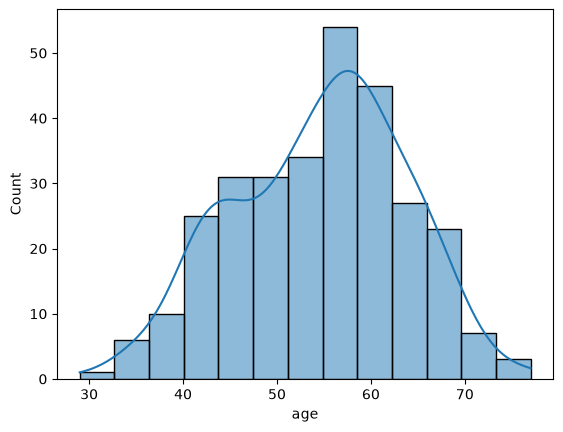

In [7]:
sns.histplot(df['age'],kde=True)

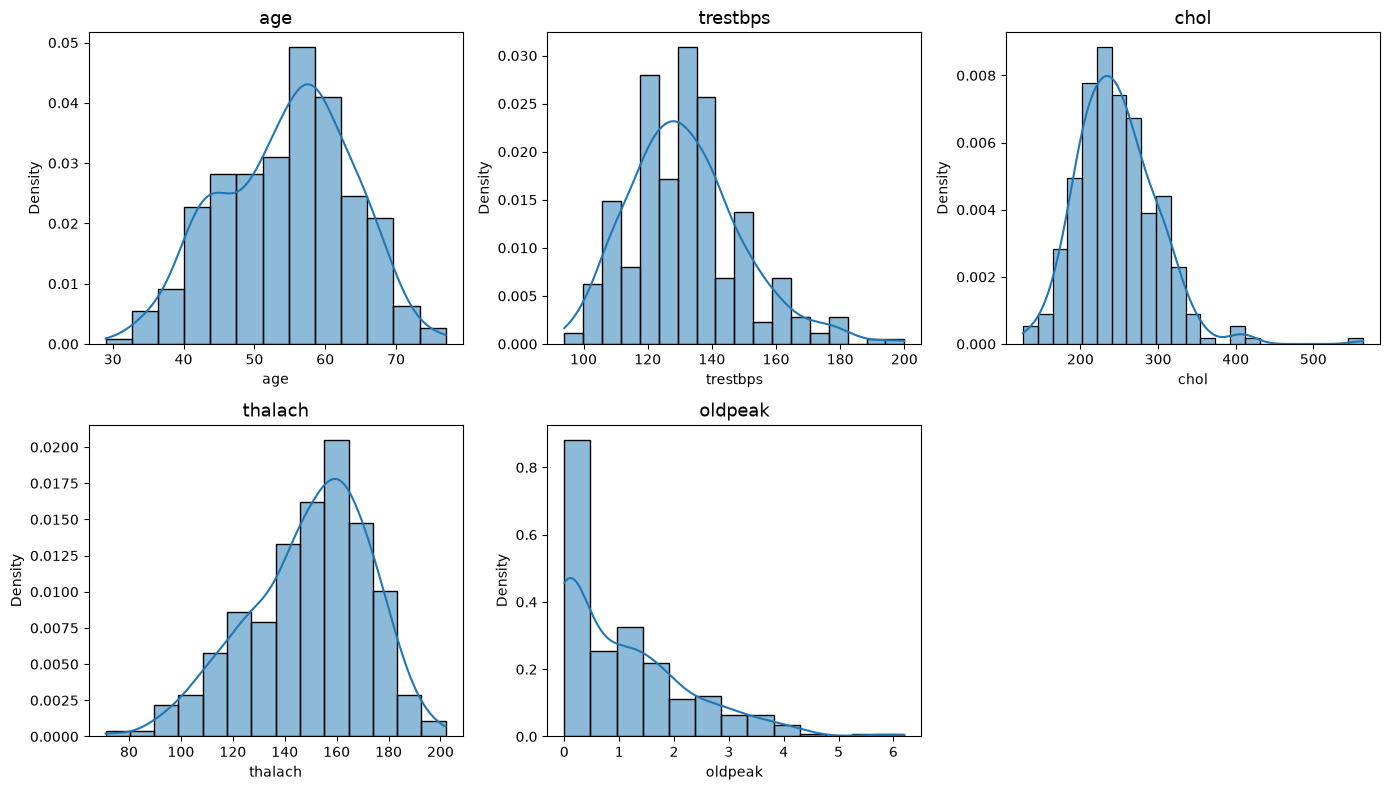

In [8]:
fig,ax=plt.subplots(2,3,figsize=(14,8))
num_col=['age','trestbps','chol','thalach','oldpeak']
for axes,col in zip(ax.flat,num_col):
    sns.histplot(data=df,x=col,kde=True,stat='density',ax=axes)
    axes.set_title(col,fontsize=13)
for axes in ax.flat[5:]:
    axes.set_visible(False)
plt.tight_layout()
plt.show()

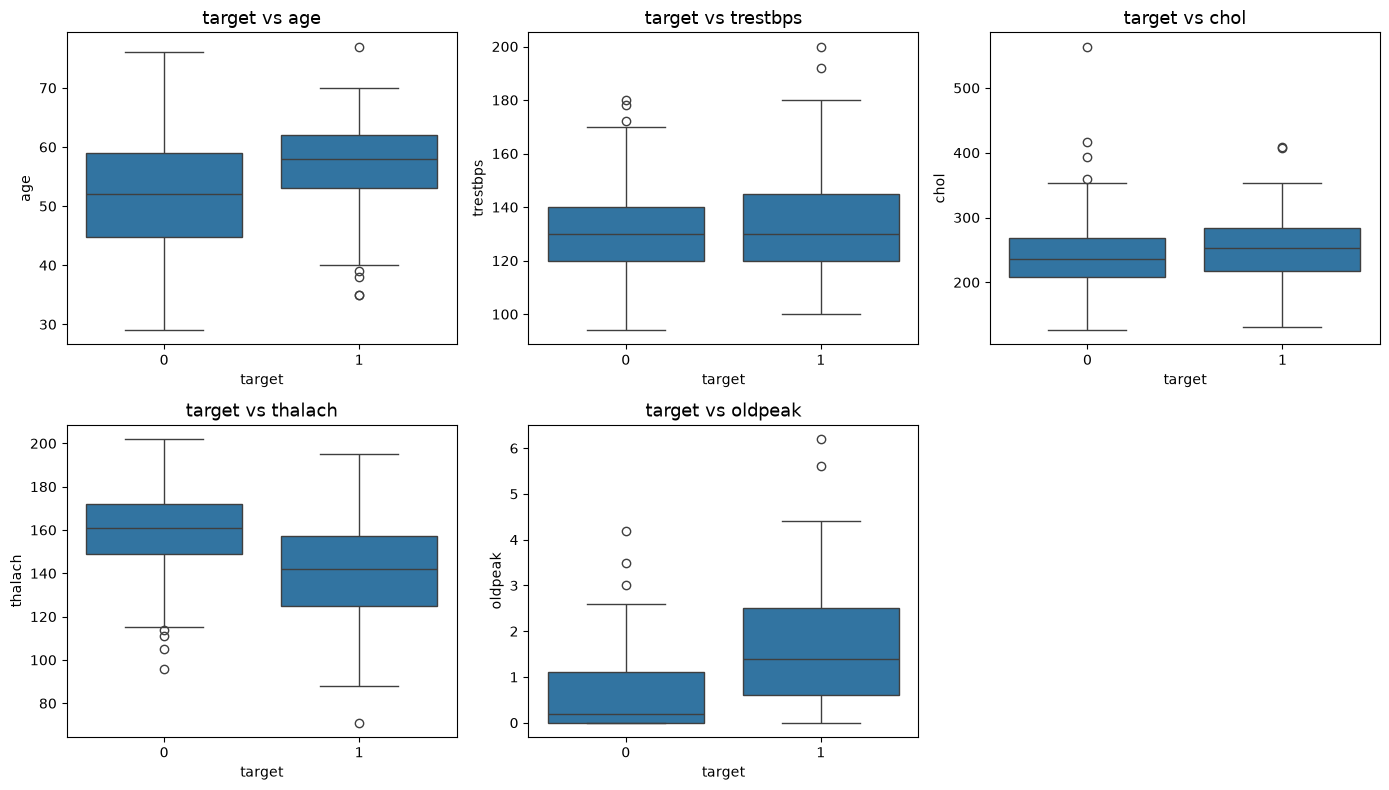

In [9]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,col in zip(axes.flat,num_col): 
    sns.boxplot(data=df,x='target',y=col,ax=ax)
    ax.set_title(f"target vs {col}",fontsize=13)
for ax in axes.flat[5:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### Continuous feature observations

In this dataset, the disease-present group has a higher average age (about 56.8 vs 52.6), lower average maximum heart rate (about 139.1 vs 158.6), and higher average `oldpeak` (about 1.59 vs 0.60). Resting blood pressure and cholesterol overlap substantially between groups. These are descriptive patterns in this sample, not causal or clinical conclusions.


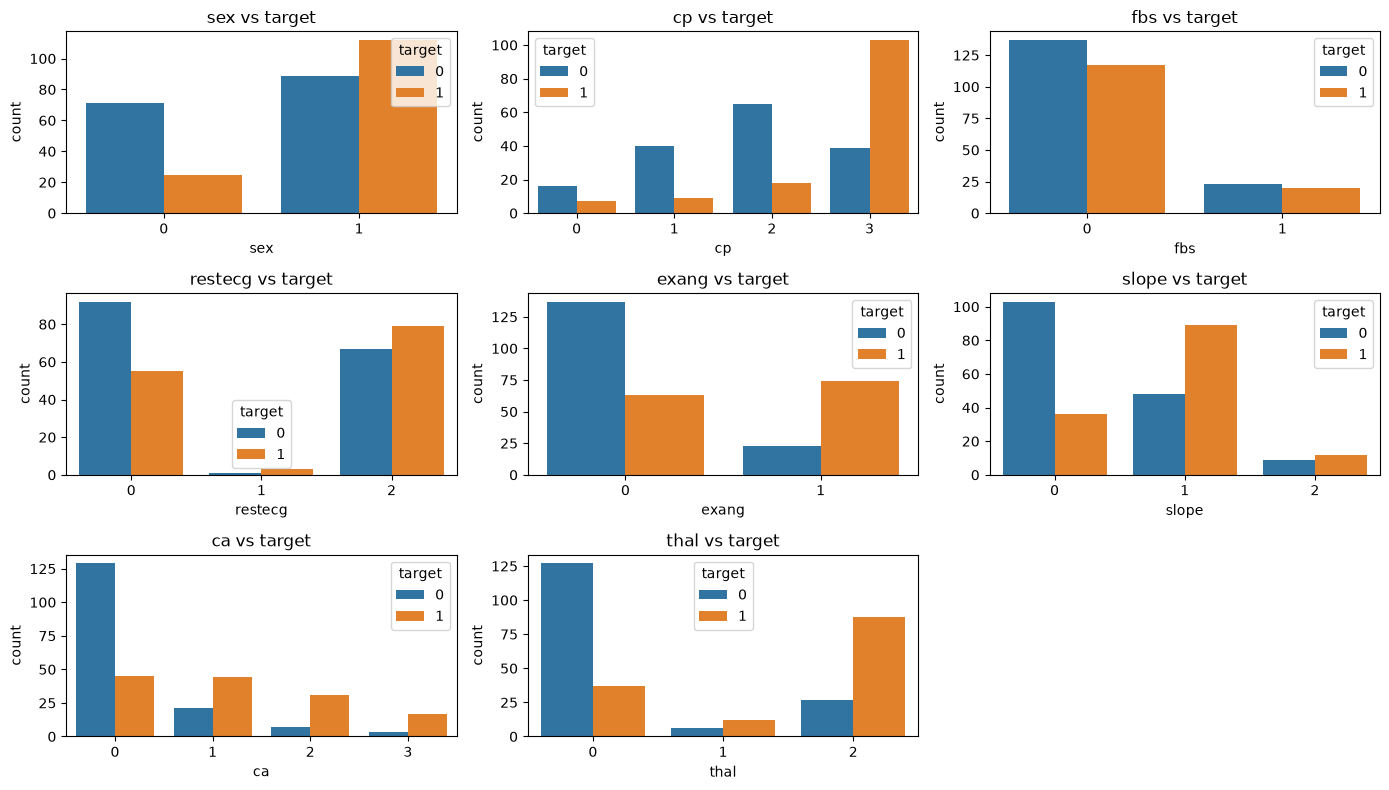

In [10]:
fig,ax=plt.subplots(3,3,figsize=(14,8))
cat_col=['sex','cp','fbs','restecg','exang','slope','ca','thal']
for axes,col in zip(ax.flat,cat_col):
    sns.countplot(data=df,x=col,hue='target',ax=axes)
    axes.set_title(f"{col} vs target") 
for axes in ax.flat[8:]:
    axes.set_visible(False)
plt.tight_layout()
plt.show()

### Categorical feature observations

The outcome proportions differ across `cp`, `exang`, `slope`, `ca`, and `thal` categories in this sample. `fbs` has nearly identical rates between its two groups. Some categories are small—especially `restecg=1` and `thal=1`—so their percentages are imprecise. `sex` is unevenly represented (96 rows with code 0 and 201 with code 1), so differences should be interpreted cautiously.


#### Bar plots: proportion of `target=1` within each category

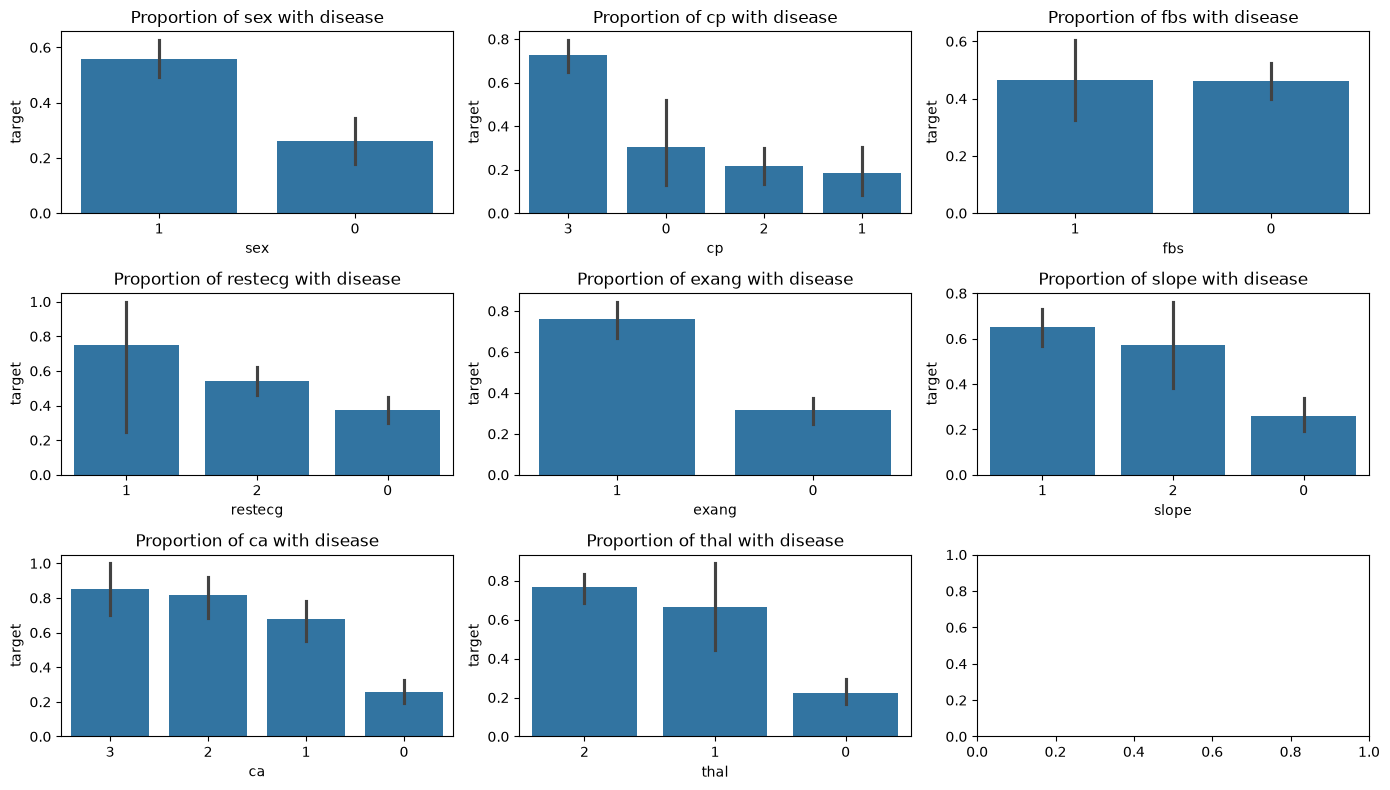

In [11]:
fig,ax=plt.subplots(3,3,figsize=(14,8))
for axes,col in zip(ax.flat,cat_col):
    order=df.groupby(col)['target'].mean().sort_values(ascending=False).index
    sns.barplot(x=col,y='target',order=order,ax=axes,data=df)
    axes.set_title(f"Proportion of {col} with disease")
plt.tight_layout()
plt.show()

### Summary: category proportions in this Cleveland file

- `cp=3` has the highest disease-present proportion (about 72.5%); the other chest-pain categories range from about 18% to 30%.
- `exang=1` has a higher disease-present proportion (about 76.3%) than `exang=0` (about 31.5%).
- `slope=1` and `slope=2` have higher proportions than `slope=0` in this sample.
- The proportion rises across `ca` values: about 25.9% for 0, 67.7% for 1, 81.6% for 2, and 85.0% for 3.
- For `thal`, the observed proportions are about 22.6% for 0, 66.7% for 1, and 76.5% for 2. The `thal=1` group is small (18 rows).
- `fbs` proportions are almost identical. The `restecg=1` category has only four rows.

These exploratory rates do not establish causation and may be unstable for small categories.


In [12]:
print(df['ca'].value_counts())
print(df['thal'].value_counts())

ca
0    174
1     65
2     38
3     20
Name: count, dtype: int64
thal
0    164
2    115
1     18
Name: count, dtype: int64


### Category-value audit

This upload contains `ca` values 0–3 and `thal` values 0–2. There are no `ca=4` records. Here, `thal=0` is a valid, common encoded category (164 records), not the unusual `thal=0` observation from the other file version. We retain the values as supplied and do not drop or reinterpret rows.


#### Pearson correlation matrix

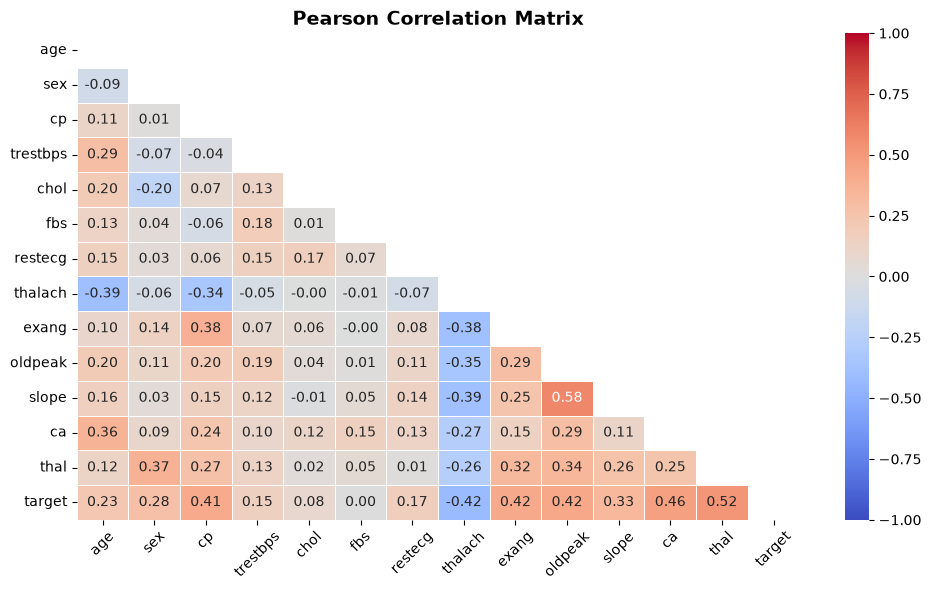

target      1.000000
thal        0.520516
ca          0.463189
oldpeak     0.424052
exang       0.421355
cp          0.408945
slope       0.333049
sex         0.278467
age         0.227075
restecg     0.166343
trestbps    0.153490
chol        0.080285
fbs         0.003167
thalach    -0.423817
Name: target, dtype: float64


In [13]:
corr_matrix=df.corr()
mask=np.triu(np.ones_like(corr_matrix,dtype=bool))
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix,mask=mask,annot=True,fmt=".2f",linewidths=0.7,linecolor="white",cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Pearson Correlation Matrix", fontsize=14, fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(corr_matrix["target"].sort_values(ascending=False))

#### Correlation heatmap notes

In this file, the largest absolute Pearson correlations with `target` are approximately: `thal` (+0.52), `ca` (+0.46), `oldpeak` (+0.42), `exang` (+0.42), `cp` (+0.41), and `thalach` (−0.42). `fbs` is close to zero. Several of these columns are encoded categories, so Pearson correlation is only a rough exploratory summary; it is not a feature-importance or causal analysis.

Among predictors, `oldpeak` and `slope` have a correlation of about +0.58, while age and `thalach` are about −0.39.


#### **Preprocessing and target separation**

In [14]:
X = df.drop(columns="target")
y = df["target"].copy()
print("Predictor matrix:", X.shape)
print("Target vector:", y.shape)


Predictor matrix: (297, 13)
Target vector: (297,)


#### Stratified train/test split

The fixed random seed makes the 80/20 split reproducible. The test partition is held aside until model selection is complete.

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
print(f"X_train-{X_train.shape},X_test-{X_test.shape},y_train-{y_train.shape},y_test-{y_test.shape}")

X_train-(237, 13),X_test-(60, 13),y_train-(237,),y_test-(60,)


In [16]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0    0.540084
1    0.459916
Name: proportion, dtype: float64
target
0    0.533333
1    0.466667
Name: proportion, dtype: float64


We compare an exploratory feature, `age_thalach = thalach - (220 - age)`, with the original predictors. It measures the difference from a rough age-based maximum-heart-rate reference. This reference is not a clinical threshold; the added feature is tested empirically rather than assumed useful.


In [17]:
from sklearn.base import BaseEstimator,TransformerMixin

class addheartfeatures(BaseEstimator,TransformerMixin):
    def __init__(self,add_age_thalach:bool=True):
        self.add_age_thalach=add_age_thalach
    def fit(self,X,y=None):
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        return self
    def transform(self,X):
        X=X.copy()
        if self.add_age_thalach:
            X["age_thalach"]=X["thalach"]-(220-X["age"])
        return X
    def get_feature_names_out(self,input_features=None):
        # needed so pipeline[:-1].get_feature_names_out() works (SHAP feature labels)
        names=list(self.feature_names_in_ if input_features is None else input_features)
        if self.add_age_thalach:
            names.append("age_thalach")
        return np.asarray(names,dtype=object)

In [18]:
Continous_cols_with_feature=['age','trestbps','chol','thalach','oldpeak','age_thalach']
Continous_cols_without_feature=['age','trestbps','chol','thalach','oldpeak']  
Categorical_cols=['cp','restecg','slope','ca','thal']
binary_cols=['sex','fbs','exang']

#### Logistic Regression pipeline: power transformation and one-hot encoding

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder,PowerTransformer) 
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

power_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("yeo_john",PowerTransformer(method="yeo-johnson",standardize=True))# Not using standard scaler because power transformer class automatically standardizes the value.
])

cat_pipeline=Pipeline([
    ("one_hot_encoder",OneHotEncoder(handle_unknown="ignore",drop="first"))
])

full_pipeline_with_feature=ColumnTransformer([
    ("transform",power_pipeline,Continous_cols_with_feature),
    ("encoding",cat_pipeline,Categorical_cols),
    ("binary","passthrough",binary_cols)
])

full_pipeline_without_feature=ColumnTransformer([
    ("transform",power_pipeline,Continous_cols_without_feature),
    ("encoding",cat_pipeline,Categorical_cols),
    ("binary","passthrough",binary_cols)
])

outer_pipeline_log_with_feature=Pipeline([
    ("feature_adder",addheartfeatures(add_age_thalach=True)),
    ("preprocessor",full_pipeline_with_feature),
    ("classifier",LogisticRegression(max_iter=2000, random_state=42))
])

outer_pipeline_log_without_feature=Pipeline([
    ("feature_adder",addheartfeatures(add_age_thalach=False)),
    ("preprocessor",full_pipeline_without_feature),
    ("classifier",LogisticRegression(max_iter=2000, random_state=42))
])


In [20]:
outer_pipeline_log_with_feature.fit(X_train,y_train)

Pipeline(steps=[('feature_adder', addheartfeatures()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('transform',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('yeo_john',
                                                                   PowerTransformer())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak',
                                                   'age_thalach']),
                                                 ('encoding',
                                                  Pipeline(steps=[('one_hot_encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['cp', 'restecg', 'slope',
                                                   'ca', 'thal']),
                                                 ('binary', 'passthrough',
                                                  ['sex', 'fbs', 'exang'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

#### Visual check of the power transform (fit on training data only)

In [21]:
cols=['age','trestbps','chol','thalach','oldpeak']
X_power=power_pipeline.fit_transform(X_train[cols])# Not adding the age_thalach feature yet to demonstrate the power pipline.
X_power_df=pd.DataFrame(
    X_power,
    columns=cols
)

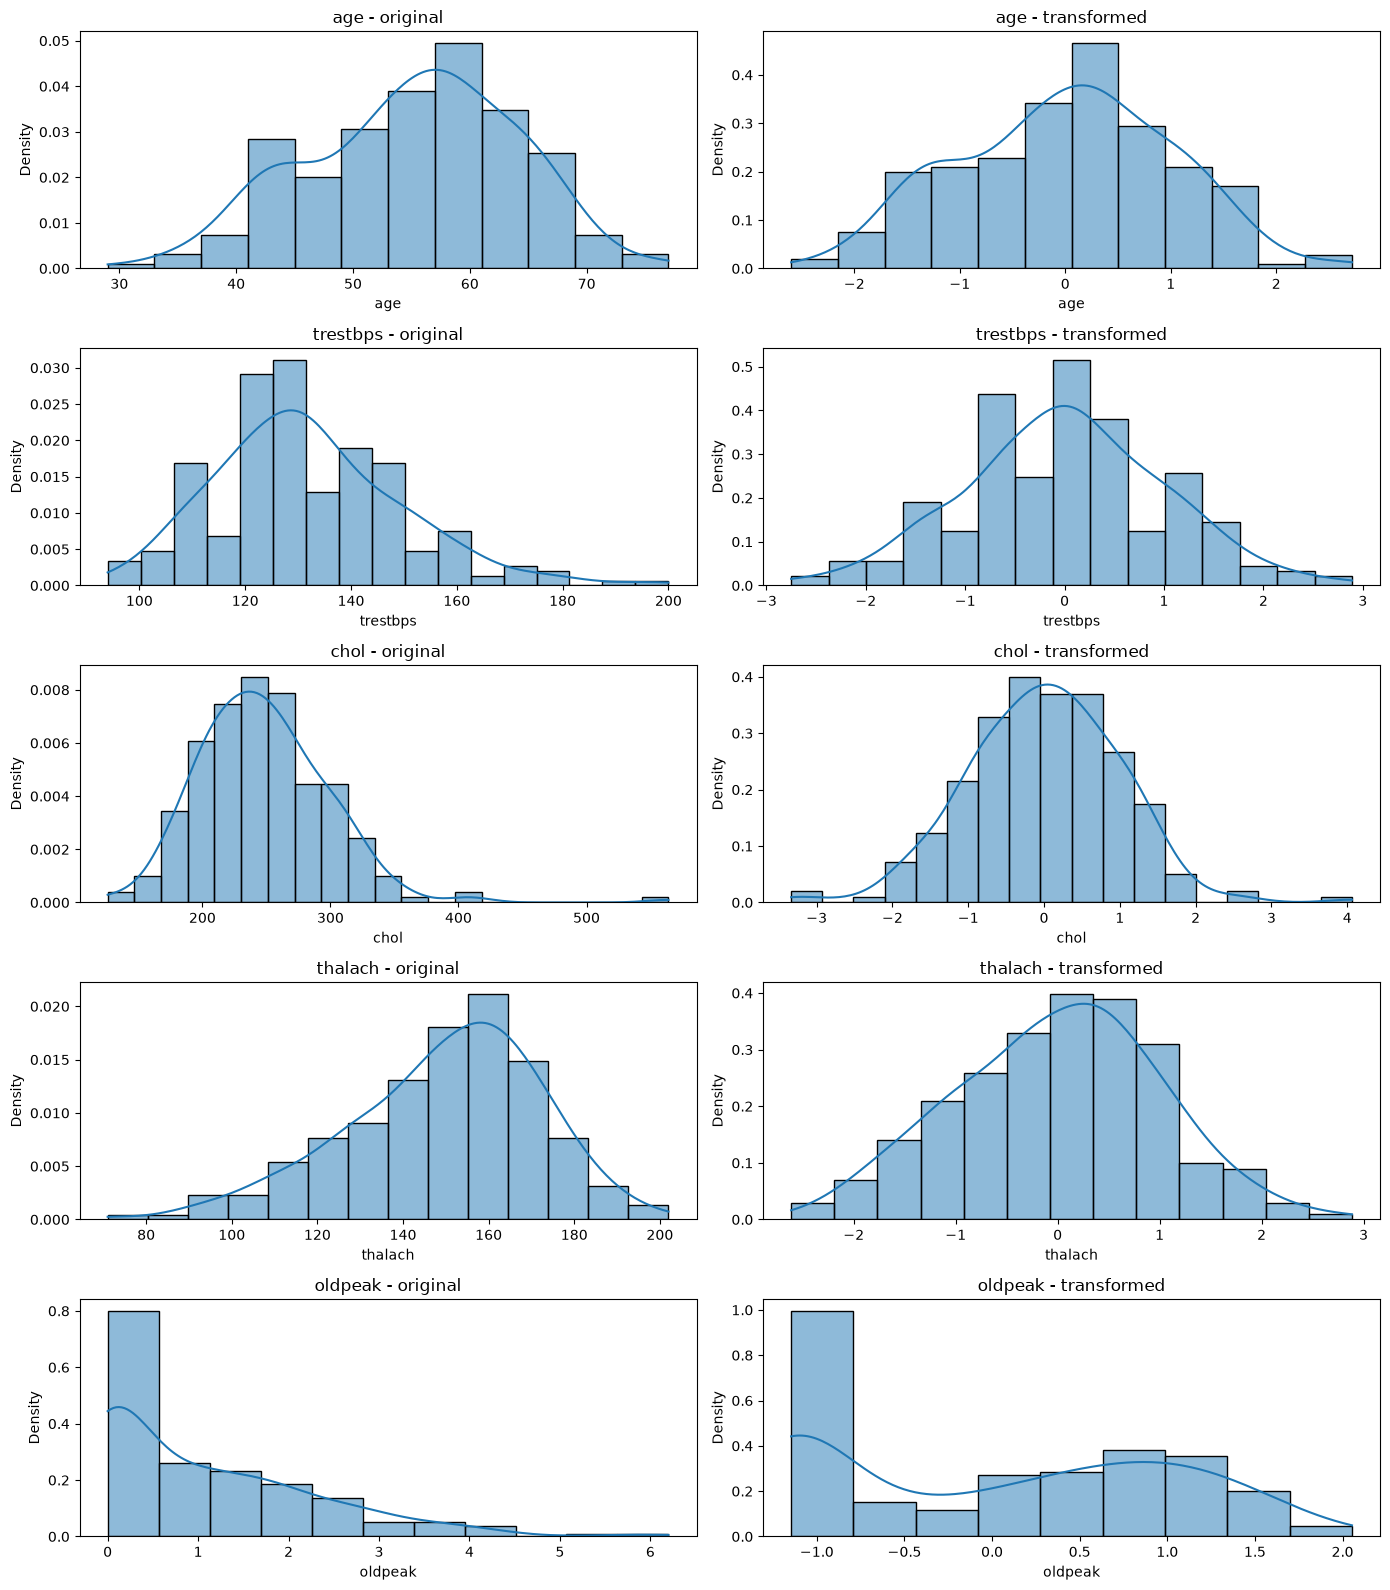

In [22]:
fig, axes = plt.subplots(5, 2, figsize=(14, 16))

for i, col in enumerate(cols):
    sns.histplot(data=X_train, x=col, kde=True, stat='density', ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} - original")

    sns.histplot(data=X_power_df, x=col, kde=True, stat='density', ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} - transformed")

plt.tight_layout()
plt.show()

#### Random Forest and XGBoost pipelines

In [23]:
from sklearn.preprocessing import (OneHotEncoder,StandardScaler)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier

continous_pipeline=Pipeline([
    ('impute',SimpleImputer(strategy="median")),
    ('scale',StandardScaler())
])

Categorical_pipeline=Pipeline([
    ('cat_impute',SimpleImputer(strategy="most_frequent")),
    ('encode',OneHotEncoder(handle_unknown="ignore"))# We are not using drop='first' because tree models do not have multicollinearity as the issue.
])

full_pipeline_rf_with_feature=ColumnTransformer([
    ('continous',continous_pipeline,Continous_cols_with_feature),
    ('cat',Categorical_pipeline,Categorical_cols),
    ('binary','passthrough',binary_cols)
])

outer_pipeline_random_forest_with_feature=Pipeline([
    ('feature_adder',addheartfeatures(add_age_thalach=True)),
    ('preprocessing',full_pipeline_rf_with_feature),
    ('random forest',RandomForestClassifier(random_state=42))
])

full_pipeline_rf_without_feature=ColumnTransformer([
    ('continous',continous_pipeline,Continous_cols_without_feature),
    ('cat',Categorical_pipeline,Categorical_cols),
    ('binary','passthrough',binary_cols)
])

outer_pipeline_random_forest_without_feature=Pipeline([
    ('feature_adder',addheartfeatures(add_age_thalach=False)),
    ('preprocessing',full_pipeline_rf_without_feature),
    ('random forest',RandomForestClassifier(random_state=42))
])

outer_pipeline_xgboost_with_feature=Pipeline([
    ('feature_adder',addheartfeatures(add_age_thalach=True)),
    ('preprocessing',full_pipeline_rf_with_feature),
    ('xgboost',XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=1))
])

outer_pipeline_xgboost_without_feature=Pipeline([
    ('feature_adder',addheartfeatures(add_age_thalach=False)),
    ('preprocessing',full_pipeline_rf_without_feature),
    ('xgboost',XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=1))
])

In [24]:
outer_pipeline_random_forest_with_feature.fit(X_train, y_train)
outer_pipeline_xgboost_with_feature.fit(X_train, y_train)

Pipeline(steps=[('feature_adder', addheartfeatures()),
                ('preprocessing',
                 ColumnTransformer(transformers=[('continous',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak',
                                                   'age_thalach']),
                                                 ('cat',
                                                  Pipeline(steps=[('cat_impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encod...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=1,
                               num_parallel_tree=None, ...))])

#### Five-fold ROC-AUC comparison with `age_thalach`

In [25]:
from sklearn.model_selection import cross_val_score
scores_log_with=cross_val_score(outer_pipeline_log_with_feature,X_train,y_train,cv=5,scoring='roc_auc')
scores_rf_with=cross_val_score(outer_pipeline_random_forest_with_feature,X_train,y_train,cv=5,scoring='roc_auc')
scores_xgb_with=cross_val_score(outer_pipeline_xgboost_with_feature,X_train,y_train,cv=5,scoring='roc_auc')


print("Logistic Regression (with feature):", scores_log_with.mean()) 
print("Random Forest (with feature):", scores_rf_with.mean())
print("XGBoost (with feature):", scores_xgb_with.mean())

Logistic Regression (with feature): 0.8909790209790212
Random Forest (with feature): 0.8804049284049285
XGBoost (with feature): 0.8692867132867133


#### Five-fold ROC-AUC comparison without `age_thalach`

In [26]:
scores_log_without = cross_val_score(outer_pipeline_log_without_feature, X_train, y_train, cv=5, scoring='roc_auc')
scores_rf_without = cross_val_score(outer_pipeline_random_forest_without_feature, X_train, y_train, cv=5, scoring='roc_auc')
scores_xgb_without = cross_val_score(outer_pipeline_xgboost_without_feature, X_train, y_train, cv=5, scoring='roc_auc')

print("Logistic Regression (without feature):", scores_log_without.mean())
print("Random Forest (without feature):", scores_rf_without.mean())
print("XGBoost (without feature):", scores_xgb_without.mean())

Logistic Regression (without feature): 0.8916896436896437
Random Forest (without feature): 0.8776939726939726
XGBoost (without feature): 0.8613226773226774


# Hyperparameter tuning

The searches use only the training partition. The stratified CV folds are shuffled with a fixed seed; ROC-AUC is the selection score.

In [27]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search_specs = [
    ("Logistic Regression (with feature)", outer_pipeline_log_with_feature,
     {"classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
      "classifier__class_weight": [None, "balanced"]}, 10),
    ("Logistic Regression (without feature)", outer_pipeline_log_without_feature,
     {"classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
      "classifier__class_weight": [None, "balanced"]}, 10),

    ("Random Forest (with feature)", outer_pipeline_random_forest_with_feature,
     {"random forest__n_estimators": [200, 400, 600],
      "random forest__max_depth": [None, 3, 5, 8],
      "random forest__min_samples_leaf": [1, 2, 4],
      "random forest__max_features": ["sqrt", 0.7]}, 12),
    ("Random Forest (without feature)", outer_pipeline_random_forest_without_feature,
     {"random forest__n_estimators": [200, 400, 600],
      "random forest__max_depth": [None, 3, 5, 8],
      "random forest__min_samples_leaf": [1, 2, 4],
      "random forest__max_features": ["sqrt", 0.7]}, 12),

    ("XGBoost (with feature)", outer_pipeline_xgboost_with_feature,
     {"xgboost__n_estimators": [100, 200, 300],
      "xgboost__max_depth": [2, 3, 4],
      "xgboost__learning_rate": [0.01, 0.05, 0.1],
      "xgboost__subsample": [0.8, 1.0],
      "xgboost__colsample_bytree": [0.8, 1.0]}, 12),
    ("XGBoost (without feature)", outer_pipeline_xgboost_without_feature,
     {"xgboost__n_estimators": [100, 200, 300],
      "xgboost__max_depth": [2, 3, 4], 
      "xgboost__learning_rate": [0.01, 0.05, 0.1],
      "xgboost__subsample": [0.8, 1.0],
      "xgboost__colsample_bytree": [0.8, 1.0]}, 12),
]

# Pin seeds for reproducibility across all 6 pipelines
for pipe in [outer_pipeline_log_with_feature, outer_pipeline_log_without_feature]:
    pipe.set_params(classifier__random_state=42, classifier__max_iter=2000)# Random_state=42 for reproducibility and max_iter=2000 because logistic regression is allowed to converge up to 2000 iterations.

for pipe in [outer_pipeline_random_forest_with_feature, outer_pipeline_random_forest_without_feature]:
    pipe.set_params(**{"random forest__random_state": 42})

for pipe in [outer_pipeline_xgboost_with_feature, outer_pipeline_xgboost_without_feature]:
    pipe.set_params(**{"xgboost__random_state": 42, "xgboost__eval_metric": "logloss"})

searches = {}
summary_rows = []

for name, estimator, param_distributions, n_iter in search_specs:
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring="roc_auc",
        cv=cv,
        refit=True,
        random_state=42,
        n_jobs=-1,
        error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search
    summary_rows.append({
        "model": name,
        "best_cv_roc_auc": search.best_score_,
        "cv_std": search.cv_results_["std_test_score"][search.best_index_],
        "best_params": search.best_params_,
    })

tuning_results = pd.DataFrame(summary_rows).sort_values(
    "best_cv_roc_auc", ascending=False
).reset_index(drop=True)

print(tuning_results)

                                   model  best_cv_roc_auc    cv_std  \
0           Random Forest (with feature)         0.897672  0.040873   
1        Random Forest (without feature)         0.893565  0.035440   
2                 XGBoost (with feature)         0.888294  0.039249   
3              XGBoost (without feature)         0.883759  0.030049   
4  Logistic Regression (without feature)         0.879618  0.035545   
5     Logistic Regression (with feature)         0.878178  0.036842   

                                         best_params  
0  {'random forest__n_estimators': 200, 'random f...  
1  {'random forest__n_estimators': 200, 'random f...  
2  {'xgboost__subsample': 0.8, 'xgboost__n_estima...  
3  {'xgboost__subsample': 0.8, 'xgboost__n_estima...  
4  {'classifier__class_weight': None, 'classifier...  
5  {'classifier__class_weight': None, 'classifier...  


In [28]:
tuning_results

,model,best_cv_roc_auc,cv_std,best_params
0,Random Forest (with feature),0.897672,0.040873,"{'random forest__n_estimators': 200, 'random f..."
1,Random Forest (without feature),0.893565,0.035440,"{'random forest__n_estimators': 200, 'random f..."
2,XGBoost (with feature),0.888294,0.039249,"{'xgboost__subsample': 0.8, 'xgboost__n_estima..."
3,XGBoost (without feature),0.883759,0.030049,"{'xgboost__subsample': 0.8, 'xgboost__n_estima..."
4,Logistic Regression (without feature),0.879618,0.035545,"{'classifier__class_weight': None, 'classifier..."
5,Logistic Regression (with feature),0.878178,0.036842,"{'classifier__class_weight': None, 'classifier..."


#### Are the model scores actually separable?
The tuning table ranks models using one 5-fold CV run, and the gaps between models are small next to the fold-to-fold spread. To see how much the ranking depends on the fold split, every tuned model is re-scored with repeated stratified CV (5 folds x 5 repeats) on the training data only. Rows with `within_1_std_of_best = True` cannot be statistically distinguished from the best model.

In [29]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
rows = []
for name, search in searches.items():
    scores = cross_val_score(search.best_estimator_, X_train, y_train,
                             cv=rcv, scoring="roc_auc", n_jobs=-1)
    rows.append({"model": name, "mean_roc_auc": scores.mean(), "std": scores.std()})

repeated_cv = pd.DataFrame(rows).sort_values("mean_roc_auc", ascending=False).reset_index(drop=True)
best_mean, best_std = repeated_cv.loc[0, "mean_roc_auc"], repeated_cv.loc[0, "std"]
repeated_cv["within_1_std_of_best"] = repeated_cv["mean_roc_auc"] >= best_mean - best_std
repeated_cv.round(4)

,model,mean_roc_auc,std,within_1_std_of_best
0,Random Forest (with feature),0.8893,0.0513,True
1,Random Forest (without feature),0.8872,0.0515,True
2,XGBoost (with feature),0.8857,0.0544,True
3,Logistic Regression (without feature),0.8829,0.0526,True
4,XGBoost (without feature),0.8825,0.0550,True
5,Logistic Regression (with feature),0.8818,0.0530,True


### Final model selection

The final model is selected as the highest mean ROC-AUC row in `tuning_results`, which is computed from training folds only. The chosen model, feature setup, best parameters, and training CV score are printed in the next cell. A very small CV difference should be treated as a practical tie. The held-out test set is reserved for the final report and is not used to select the model.

This dataset contains 297 records, so estimates are uncertain. Model scores are not calibrated clinical probabilities and do not establish clinical validity.

The repeated-CV table above shows whether the candidates can be separated at all. Where several rows are flagged `within_1_std_of_best = True`, the choice between them rests on interpretability and simplicity as much as on the score, and the report should say so. These CV scores are slightly optimistic for every model alike, because the hyperparameters were tuned on the same training data.


In [30]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, classification_report)

selected_search_name = tuning_results.iloc[0]["model"]
final_search = searches[selected_search_name]
final_model = final_search.best_estimator_  # refit on all training rows by RandomizedSearchCV
feature_setup = "with age_thalach" if "(with feature)" in selected_search_name else "without age_thalach"

# The Cleveland holdout is scored after CV-based model selection is complete.
y_test_pred = final_model.predict(X_test)
y_test_score = final_model.predict_proba(X_test)[:, 1]
final_cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
final_test_metrics = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred, zero_division=0),
    "recall_sensitivity": recall_score(y_test, y_test_pred, zero_division=0),
    "specificity": final_cm[0, 0] / final_cm[0].sum(),
    "f1": f1_score(y_test, y_test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_test_score),
}
print(f"Selected model: {selected_search_name} ({feature_setup})")
print("Best training CV ROC-AUC:", final_search.best_score_)
print("Best parameters:", final_search.best_params_)
print("Test metrics:", {k: round(float(v), 4) for k, v in final_test_metrics.items()})
print("Confusion matrix [rows=actual 0/1, columns=predicted 0/1]:\n", final_cm)
print("\nClassification report:\n", classification_report(y_test, y_test_pred, zero_division=0))


Selected model: Random Forest (with feature) (with age_thalach)
Best training CV ROC-AUC: 0.8976723276723277
Best parameters: {'random forest__n_estimators': 200, 'random forest__min_samples_leaf': 1, 'random forest__max_features': 'sqrt', 'random forest__max_depth': 3}
Test metrics: {'accuracy': 0.85, 'precision': 0.9524, 'recall_sensitivity': 0.7143, 'specificity': 0.9688, 'f1': 0.8163, 'roc_auc': 0.9386}
Confusion matrix [rows=actual 0/1, columns=predicted 0/1]:
 [[31  1]
 [ 8 20]]

Classification report:
               precision    recall  f1-score   support

           0       0.79      0.97      0.87        32
           1       0.95      0.71      0.82        28

    accuracy                           0.85        60
   macro avg       0.87      0.84      0.84        60
weighted avg       0.87      0.85      0.85        60



## Final holdout plots

These plots reuse the selected model's test predictions and scores from the evaluation cell above.

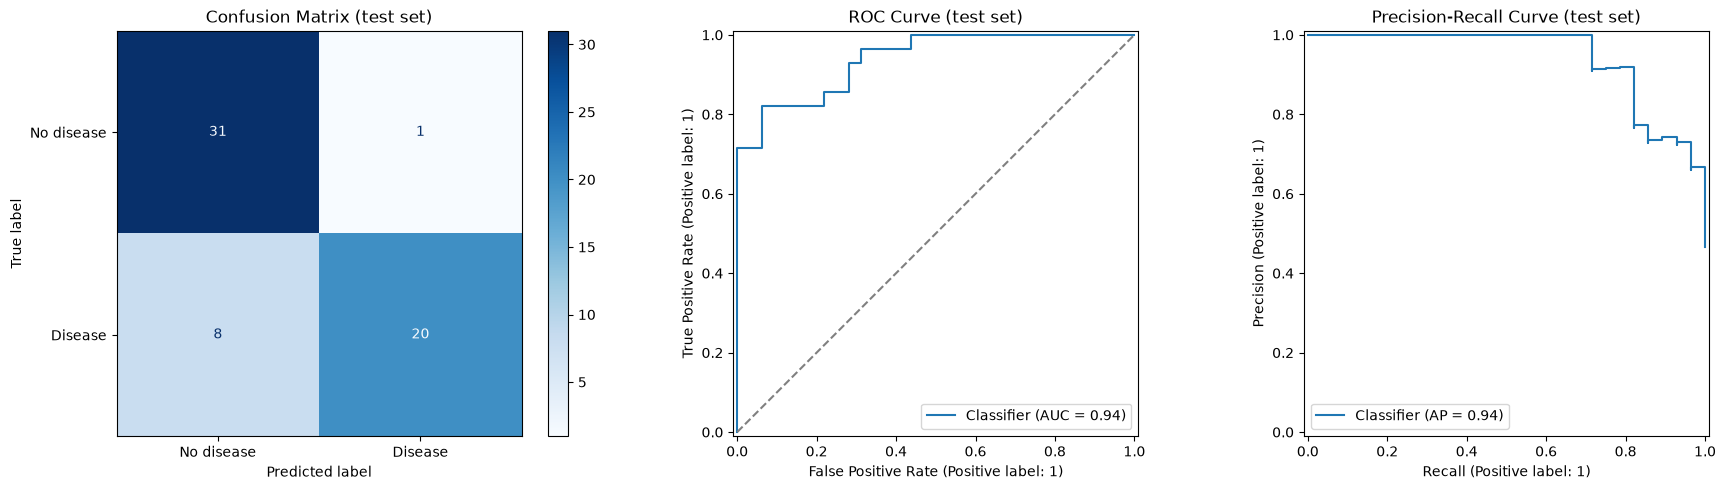

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["No disease", "Disease"],
    cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix (test set)")

RocCurveDisplay.from_predictions(y_test, y_test_score, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("ROC Curve (test set)")

PrecisionRecallDisplay.from_predictions(y_test, y_test_score, ax=axes[2])
axes[2].set_title("Precision-Recall Curve (test set)")

plt.tight_layout()
plt.show()

## Threshold analysis (precision/recall)

Out-of-fold scores are generated on training rows only. This illustrates how changing the cutoff changes precision and recall; it does not define a clinical decision threshold. The holdout set is not used to choose a threshold.


In [32]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

cv_proba = cross_val_predict(final_model, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.2, 0.85, 0.05):
    pred = (cv_proba >= t).astype(int)
    rows.append({
        "threshold": round(float(t), 2),
        "precision": precision_score(y_train, pred, zero_division=0),
        "recall": recall_score(y_train, pred),
        "f1": f1_score(y_train, pred),
    })

threshold_table = pd.DataFrame(rows)
threshold_table.round(3)

,threshold,precision,recall,f1
0,0.20,0.565,0.963,0.712
1,0.25,0.595,0.945,0.730
2,0.30,0.647,0.927,0.762
3,0.35,0.693,0.872,0.772
4,0.40,0.721,0.807,0.762
5,0.45,0.746,0.780,0.762
6,0.50,0.822,0.761,0.790
7,0.55,0.875,0.706,0.782
8,0.60,0.919,0.624,0.743
9,0.65,0.938,0.550,0.694


## Model comparison table

For each model family, the feature variant is chosen by training CV. Test-set results below are reporting-only; do not use them to choose or retune a model.


In [33]:
from sklearn.metrics import accuracy_score, roc_auc_score

model_options = {
    "Logistic Regression": ["Logistic Regression (with feature)", "Logistic Regression (without feature)"],
    "Random Forest": ["Random Forest (with feature)", "Random Forest (without feature)"],
    "XGBoost": ["XGBoost (with feature)", "XGBoost (without feature)"],
}
comparison_rows = []
for model_name, options in model_options.items():
    best_name = max(options, key=lambda name: searches[name].best_score_)
    search = searches[best_name]
    model = search.best_estimator_
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    comparison_rows.append({
        "Model": model_name,
        "Selected feature setup": "with age_thalach" if "(with feature)" in best_name else "without age_thalach",
        "CV ROC-AUC": search.best_score_,
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    })
comparison_df = pd.DataFrame(comparison_rows).round(3)
comparison_df


,Model,Selected feature setup,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,F1
0,Logistic Regression,without age_thalach,0.880,0.970,0.917,1.000,0.821,0.902
1,Random Forest,with age_thalach,0.898,0.939,0.850,0.952,0.714,0.816
2,XGBoost,with age_thalach,0.888,0.941,0.850,0.952,0.714,0.816


## Save Cleveland-specific artifacts

Artifacts are saved under `models/heart_cleveland/` so they remain separate from files produced with the other dataset. The fitted pipeline is stored with an importable transformer. The training background CSV contains predictors only (no target column), ready for later SHAP work.


In [34]:
import os, sys, copy, json, joblib
from importlib.metadata import version, PackageNotFoundError

artifact_dir = "../models/heart_cleveland"
os.makedirs(artifact_dir, exist_ok=True)
os.makedirs("../utils", exist_ok=True)

# Put the custom transformer in an importable module so joblib can load it later.
preprocessing_code = '''import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin


class addheartfeatures(BaseEstimator, TransformerMixin):
    def __init__(self, add_age_thalach: bool = True):
        self.add_age_thalach = add_age_thalach

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        if self.add_age_thalach:
            X["age_thalach"] = X["thalach"] - (220 - X["age"])
        return X

    def get_feature_names_out(self, input_features=None):
        names = list(self.feature_names_in_ if input_features is None else input_features)
        if self.add_age_thalach:
            names.append("age_thalach")
        return np.asarray(names, dtype=object)
'''
with open("../utils/preprocessing.py", "w", encoding="utf-8") as f:
    f.write(preprocessing_code)
open("../utils/__init__.py", "a", encoding="utf-8").close()

sys.path.insert(0, os.path.abspath(".."))
from utils.preprocessing import addheartfeatures as ImportableAddFeatures

model_to_save = copy.deepcopy(final_model)
original_adder = model_to_save.named_steps["feature_adder"]
model_to_save.steps[0] = ("feature_adder", ImportableAddFeatures(
    add_age_thalach=original_adder.add_age_thalach).fit(X_train))

# Confirm that replacing the notebook-local class did not change predictions,
# and that feature names are available (SHAP needs them).
assert np.allclose(model_to_save.predict_proba(X_test), final_model.predict_proba(X_test))
feature_names_out = list(model_to_save[:-1].get_feature_names_out())
print("Features seen by the classifier:", len(feature_names_out))

joblib.dump(model_to_save, os.path.join(artifact_dir, "heart_risk_pipeline.joblib"))
comparison_df.to_csv(os.path.join(artifact_dir, "model_comparison.csv"), index=False)
threshold_table.to_csv(os.path.join(artifact_dir, "threshold_table.csv"), index=False)
X_train.to_csv(os.path.join(artifact_dir, "X_train.csv"), index=False)   # predictors only, SHAP background data
df.to_csv("../data/heart_cleveland_clean.csv", index=False)

# Metadata for the Streamlit form: column order, input ranges and category labels.
# The labels below are for THIS file's coding (thal is recoded 0/1/2 here; cp, restecg and slope follow the UCI order).
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
metadata = {
    "model": selected_search_name,
    "uses_age_thalach": bool(original_adder.add_age_thalach),
    "target_meaning": "1 = heart disease present, 0 = no heart disease",
    "feature_columns": list(X_train.columns),
    "numeric_ranges": {c: {"min": float(df[c].min()), "max": float(df[c].max()),
                           "median": float(df[c].median())} for c in numeric_cols},
    "category_labels": {
        "sex": {"0": "Female", "1": "Male"},
        "fbs": {"0": "No (<= 120 mg/dl)", "1": "Yes (> 120 mg/dl)"},
        "exang": {"0": "No", "1": "Yes"},
        "cp": {"0": "Typical angina", "1": "Atypical angina", "2": "Non-anginal pain", "3": "Asymptomatic"},
        "restecg": {"0": "Normal", "1": "ST-T wave abnormality", "2": "Left ventricular hypertrophy"},
        "slope": {"0": "Upsloping", "1": "Flat", "2": "Downsloping"},
        "thal": {"0": "Normal", "1": "Fixed defect", "2": "Reversible defect"},
        "ca": {"0": "0 vessels", "1": "1 vessel", "2": "2 vessels", "3": "3 vessels"},
    },
    "default_threshold": 0.5,
    "test_metrics": {k: round(float(v), 4) for k, v in final_test_metrics.items()},
}
with open(os.path.join(artifact_dir, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

# requirements.txt: the scikit-learn version must match when the saved model is loaded elsewhere.
req = []
for pkg in ["streamlit", "pandas", "numpy", "scikit-learn", "joblib", "matplotlib", "shap"]:
    try:
        req.append(f"{pkg}=={version(pkg)}")
    except PackageNotFoundError:
        req.append(pkg)   # not installed here -> left unpinned
if not os.path.exists("../requirements.txt"):
    with open("../requirements.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(req) + "\n")

print("Saved Cleveland artifacts:", sorted(os.listdir(artifact_dir)))

Features seen by the classifier: 26
Saved Cleveland artifacts: ['X_train.csv', 'heart_risk_pipeline.joblib', 'metadata.json', 'model_comparison.csv', 'threshold_table.csv']


In [35]:
# Load the saved pipeline in a separate Python process, as the app will, using float inputs like Streamlit sends.
import subprocess

test_script = """
import json, joblib, pandas as pd
d = "models/heart_cleveland/"
m = joblib.load(d + "heart_risk_pipeline.joblib")
meta = json.load(open(d + "metadata.json"))
row = pd.read_csv(d + "X_train.csv").head(1).astype(float)[meta["feature_columns"]]
print("risk score (class 1 = disease):", round(float(m.predict_proba(row)[0, 1]), 4))
print("transformed feature names:", len(m[:-1].get_feature_names_out()))
"""
check = subprocess.run([sys.executable, "-c", test_script], cwd="..", capture_output=True, text=True)
if check.returncode != 0:
    raise RuntimeError(check.stderr)
print(check.stdout)

risk score (class 1 = disease): 0.7348
transformed feature names: 26



### SHAP EXPLAINABILITY

SHAP splits one prediction into additive contributions from each feature: `base value + sum of contributions = the model's output`. The explainer is built on the **saved** pipeline (the same file the Streamlit app will load), using the training data as background. One-hot encoded columns are summed back into their original feature, so each explanation reads as "Chest pain = Asymptomatic", not as a list of dummy columns.

These explanations describe what the **model** relied on in this small dataset. They are not medical causes, and the score is not a calibrated clinical probability.

In [36]:
import os, sys

os.makedirs("../utils", exist_ok=True)

explainability_code = '''import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

PRETTY = {
    "age": "Age",
    "trestbps": "Resting blood pressure",
    "chol": "Cholesterol",
    "thalach": "Max heart rate",
    "oldpeak": "ST depression",
    "age_thalach": "Heart rate vs age-expected max",
    "sex": "Sex (male)",
    "fbs": "Fasting blood sugar > 120",
    "exang": "Exercise-induced angina",
    "cp": "Chest pain",
    "restecg": "Resting ECG",
    "slope": "ST slope",
    "ca": "Major vessels",
    "thal": "Thal test",
}
TREE_MODELS = ("RandomForestClassifier", "XGBClassifier", "GradientBoostingClassifier", "ExtraTreesClassifier")


def _dense(a):
    return a.toarray() if hasattr(a, "toarray") else np.asarray(a)


def readable_name(raw_name, labels):
    """'cat__cp_3' -> 'Chest pain: Asymptomatic'; 'continous__oldpeak' -> 'ST depression'."""
    base = raw_name.split("__", 1)[1]
    if base in PRETTY:
        return PRETTY[base]
    col, code = base.rsplit("_", 1)
    code = str(int(float(code)))
    return PRETTY.get(col, col) + ": " + labels.get(col, {}).get(code, code)


def _group_of(raw_name):
    """'cat__cp_3' -> 'cp'; 'continous__oldpeak' -> 'oldpeak'."""
    base = raw_name.split("__", 1)[1]
    return base if base in PRETTY else base.rsplit("_", 1)[0]


def class1_values(explainer, X):
    """SHAP values for class 1 (disease), shape (n_rows, n_features)."""
    sv = explainer.shap_values(X)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return sv


def load_artifacts(artifact_dir):
    model = joblib.load(os.path.join(artifact_dir, "heart_risk_pipeline.joblib"))
    with open(os.path.join(artifact_dir, "metadata.json"), encoding="utf-8") as f:
        meta = json.load(f)
    X_train = pd.read_csv(os.path.join(artifact_dir, "X_train.csv"))[meta["feature_columns"]]
    pre, clf = model[:-1], model[-1]
    background = _dense(pre.transform(X_train))
    if type(clf).__name__ in TREE_MODELS:
        explainer = shap.TreeExplainer(clf)
    else:
        explainer = shap.LinearExplainer(clf, background)
    labels = meta["category_labels"]
    raw_names = list(pre.get_feature_names_out())
    names = [readable_name(n, labels) for n in raw_names]
    groups = [_group_of(n) for n in raw_names]
    orig_features = list(dict.fromkeys(groups))
    G = np.array([[1.0 if g == o else 0.0 for o in orig_features] for g in groups])  # one-hot column -> original feature
    scale = "probability" if type(clf).__name__ == "RandomForestClassifier" else "log-odds"
    return {"model": model, "pre": pre, "clf": clf, "meta": meta, "X_train": X_train,
            "background": background, "explainer": explainer, "names": names, "scale": scale,
            "orig_features": orig_features, "G": G}


def global_importance(art):
    """Mean |SHAP| per ORIGINAL feature (one-hot columns are summed back together first)."""
    sv = class1_values(art["explainer"], art["background"])
    agg = sv @ art["G"]
    return (pd.DataFrame({"feature": [PRETTY[o] for o in art["orig_features"]],
                          "mean_abs_shap": np.abs(agg).mean(axis=0)})
            .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))


def plot_global(art, max_display=15):
    """Returns (bar figure per original feature, beeswarm figure per encoded column)."""
    imp = global_importance(art).head(max_display).iloc[::-1]
    fig_bar, ax = plt.subplots(figsize=(8, 5))
    ax.barh(imp["feature"], imp["mean_abs_shap"], color="#1f77b4")
    ax.set_xlabel("Average impact on the model's score (mean |SHAP|)")
    ax.set_title("Which features matter most overall")
    fig_bar.tight_layout()
    sv = class1_values(art["explainer"], art["background"])
    plt.figure()
    shap.summary_plot(sv, art["background"], feature_names=art["names"],
                      max_display=max_display, show=False)
    plt.title("Each dot is a patient (red = high value, or category present)")
    fig_swarm = plt.gcf(); fig_swarm.tight_layout()
    return fig_bar, fig_swarm


def explain_patient(art, patient):
    """patient: dict with the 13 raw columns. Contributions are per original feature, labelled with the patient's value."""
    row = pd.DataFrame([patient])[art["meta"]["feature_columns"]]
    risk = float(art["model"].predict_proba(row)[0, 1])
    engineered = art["model"][0].transform(row)          # adds age_thalach when the model uses it
    x = _dense(art["pre"].transform(row))
    sv = class1_values(art["explainer"], x)[0]
    agg = sv @ art["G"]
    labels = art["meta"]["category_labels"]
    shown = []
    for o in art["orig_features"]:
        v = engineered[o].iloc[0]
        text = labels[o].get(str(int(v)), str(int(v))) if o in labels else f"{v:g}"
        shown.append(f"{PRETTY[o]} = {text}")
    base = float(np.ravel(art["explainer"].expected_value)[-1])
    table = (pd.DataFrame({"feature": shown, "shap": agg})
             .assign(abs_shap=lambda d: d["shap"].abs())
             .sort_values("abs_shap", ascending=False)
             .drop(columns="abs_shap").reset_index(drop=True))
    return {"risk": risk, "base": base, "agg": agg, "names": shown, "table": table}


def check_additivity(art, result):
    """base + sum(SHAP) must equal the model output (probability for Random Forest, log-odds otherwise)."""
    lhs = result["base"] + float(result["agg"].sum())
    rhs = result["risk"] if art["scale"] == "probability" else float(np.log(result["risk"] / (1 - result["risk"])))
    return lhs, rhs


def explain_sentence(result, top_n=3):
    t = result["table"]
    up = t[t["shap"] > 0].head(top_n)["feature"].tolist()
    down = t[t["shap"] < 0].head(top_n)["feature"].tolist()
    text = f"Model-estimated risk score: {result['risk']:.0%}."
    if up:
        text += " Factors that pushed the score up: " + ", ".join(up) + "."
    if down:
        text += " Factors that pushed it down: " + ", ".join(down) + "."
    return text


def plot_patient(art, result, max_display=10):
    """Waterfall plot for one patient. Returns the figure."""
    expl = shap.Explanation(values=result["agg"], base_values=result["base"],
                            feature_names=result["names"])
    plt.figure()
    shap.plots.waterfall(expl, max_display=max_display, show=False)
    return plt.gcf()
'''
with open("../utils/explainability.py", "w", encoding="utf-8") as f:
    f.write(explainability_code)
open("../utils/__init__.py", "a", encoding="utf-8").close()
print("Wrote ../utils/explainability.py")

Wrote ../utils/explainability.py


### Global importance — which features matter most overall

c:\Users\ASUS\anaconda3\envs\heartrisk\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model explained: Random Forest (with feature)
SHAP values are on the probability scale, for class 1 (heart disease)


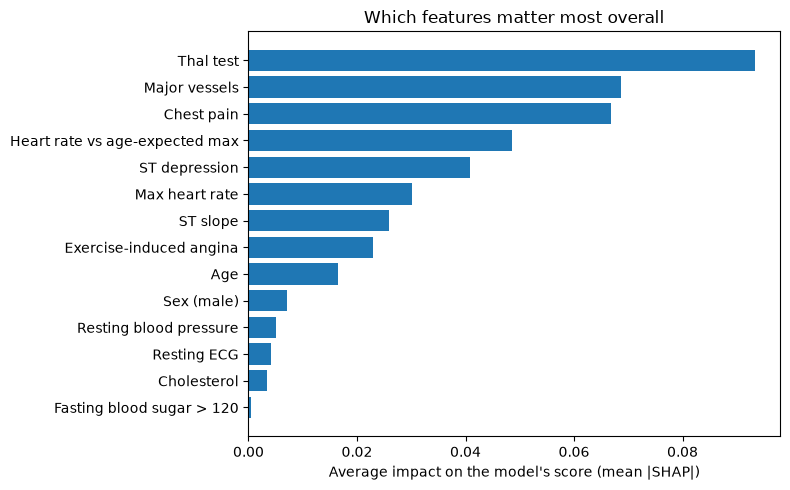

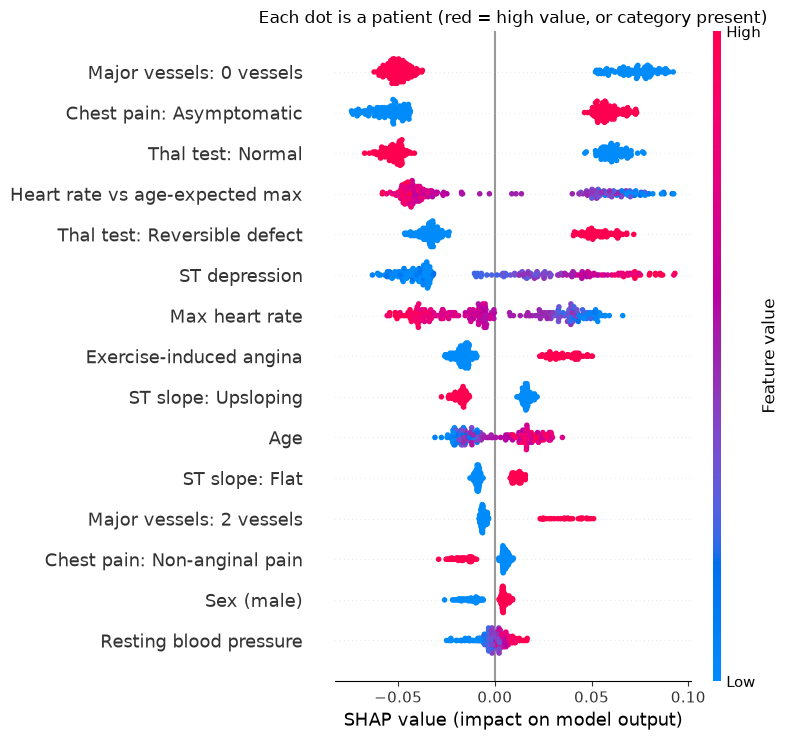

In [37]:
import sys, os
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))   # so the saved pipeline can import utils.preprocessing

import importlib
import utils.explainability as xai
importlib.reload(xai)

art = xai.load_artifacts("../models/heart_cleveland")
print("Model explained:", art["meta"]["model"])
print("SHAP values are on the", art["scale"], "scale, for class 1 (heart disease)")

fig_bar, fig_swarm = xai.plot_global(art, max_display=15)
plt.show()

In [38]:
# Global importance as a table (useful for the report)
import numpy as np
import pandas as pd

global_importance = xai.global_importance(art)
global_importance.round(4)

,feature,mean_abs_shap
0,Thal test,0.0933
1,Major vessels,0.0687
2,Chest pain,0.0668
3,Heart rate vs age-expected max,0.0486
4,ST depression,0.0408
5,Max heart rate,0.0301
6,ST slope,0.0259
7,Exercise-induced angina,0.0230
8,Age,0.0165
9,Sex (male),0.0071


### Global SHAP observations
*(Random Forest, SHAP values on the probability scale for class 1 = heart disease. "Mean |SHAP|" is the average amount a feature moves the predicted probability.)*

- **Three features dominate:** thal test (~0.093), number of major vessels (~0.069) and chest pain type (~0.067). On average, thal alone shifts a patient's predicted score by about 9 percentage points. This matches the EDA, where `ca`, `thal` and `cp` were the strongest categorical separators.
- **Next tier:** the engineered heart rate vs age-expected max (~0.049), ST depression (~0.041), max heart rate (~0.030), ST slope (~0.026) and exercise-induced angina (~0.023).
- **Weak features:** age, sex, resting blood pressure, resting ECG, cholesterol and fasting blood sugar each contribute little (fasting blood sugar is close to zero). This also matches the EDA, where `chol`, `trestbps` and `fbs` showed little separation.
- **Directions in the dot plot** (red = high value or category present):
  - Higher risk: asymptomatic chest pain, reversible thal defect, exercise-induced angina, higher ST depression, flat ST slope, 2 vessels, male sex.
  - Lower risk: 0 vessels, normal thal result, upsloping ST slope, non-anginal chest pain, higher max heart rate, and a higher heart rate relative to age.
  - These directions agree with the EDA (for example, 72.5% of asymptomatic patients had disease).
- **Caution on the engineered feature:** `age_thalach` ranks 4th by SHAP importance, but the earlier experiment showed no measurable CV improvement from adding it. SHAP shows what the model *relies on*, not what it *gains*. The feature is also correlated with `age` and `thalach`, so the credit is shared among the three.

### Local explanation — why did the model give this patient this score?

Model-estimated risk score: 94%. Factors that pushed the score up: Thal test = Reversible defect, Major vessels = 2 vessels, ST depression = 3.

                                feature   shap
0         Thal test = Reversible defect  0.097
1             Major vessels = 2 vessels  0.075
2                     ST depression = 3  0.060
3             Chest pain = Asymptomatic  0.059
4  Heart rate vs age-expected max = -48  0.057
5                  Max heart rate = 110  0.040
6         Exercise-induced angina = Yes  0.027
7                       ST slope = Flat  0.025


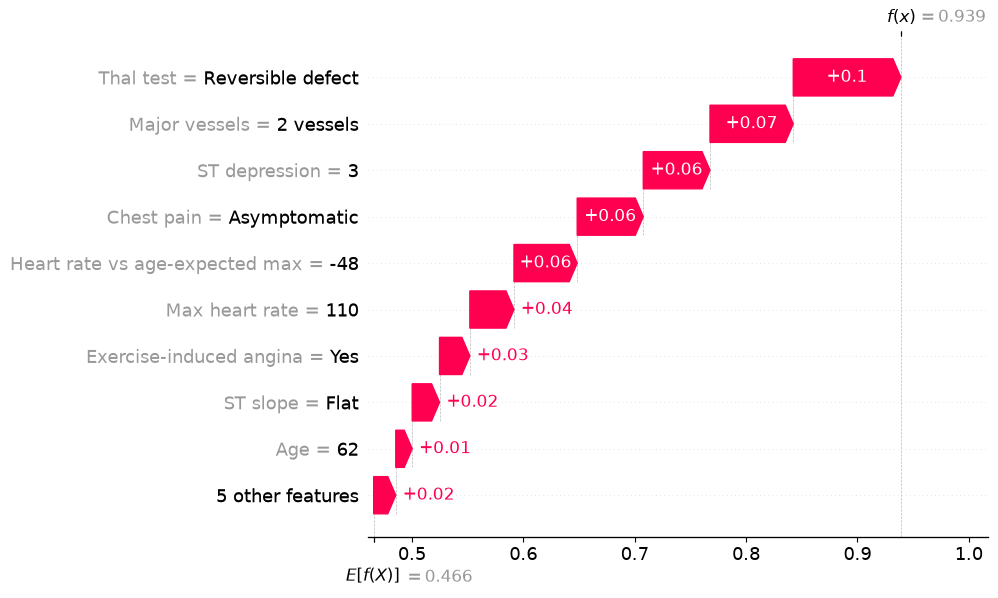


base + sum(SHAP) = 0.939 | model output = 0.939 (probability scale)


In [39]:
# One patient, entered like the Streamlit form will enter it (edit the values to try others)
patient = {
    "age": 62.0, "sex": 1, "cp": 3, "trestbps": 150.0, "chol": 270.0, "fbs": 0, "restecg": 2,
    "thalach": 110.0, "exang": 1, "oldpeak": 3.0, "slope": 1, "ca": 2, "thal": 2,
}

result = xai.explain_patient(art, patient)
print(xai.explain_sentence(result))
print()
print(result["table"].head(8).round(3))

fig_patient = xai.plot_patient(art, result, max_display=10)
plt.show()

# Sanity check: base value + sum of SHAP values should equal the model's own output
lhs, rhs = xai.check_additivity(art, result)
print("\nbase + sum(SHAP) =", round(lhs, 4), "| model output =", round(rhs, 4), f"({art['scale']} scale)")

### Local SHAP observation (example patient)
The example patient (62 years old, male, asymptomatic chest pain, reversible thal defect, 2 vessels, ST depression 3, max heart rate 110) gets a model-estimated risk score of **0.939**, compared with an average of **0.466** across the training data.

Every shown factor pushed the score up. The largest were thal = reversible defect (+0.10), 2 major vessels (+0.07), ST depression = 3 (+0.06), asymptomatic chest pain (+0.06) and a heart rate 48 below the age-expected maximum (+0.06). The contributions add up exactly: 0.466 + the sum of the contributions = 0.939.

This is how the Streamlit Predict page will explain each prediction.

### Limitations of the explanations
- SHAP describes how the **model** behaves on this dataset. It does not show medical cause and effect.
- The dataset is small (297 patients), so importance values would shift somewhat with different data.
- The score is a model estimate, not a calibrated clinical probability. This is an educational tool, not a diagnosis.

In [40]:
# Save the held-out test predictions so the Streamlit app can draw ROC / precision-recall curves
import pandas as pd

pd.DataFrame({
    "y_true": y_test.to_numpy(),
    "y_score": final_model.predict_proba(X_test)[:, 1],
}).to_csv("../models/heart_cleveland/test_predictions.csv", index=False)
print("Saved ../models/heart_cleveland/test_predictions.csv")

Saved ../models/heart_cleveland/test_predictions.csv
